**Submission By: Nhooja Roy**

**Date: November 05 2026**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def operate_A(u, h):
    u = np.asarray(u, dtype = float)
    res = 2 * u
    res[1:] -= u[:-1]
    res[:-1] -= u[1:]

    return res/ h**2

##Checking:
n = 8
h = 1.0 / (n + 1)
x = np.arange(1, n + 1) * h
u = 0.5 * x * (1.0 - x)
Au = operate_A(u, h)

print(Au)


[1. 1. 1. 1. 1. 1. 1. 1.]


**Jacobi Implementation**

Need to use iteration of guesses dependent on the previous value as:
$$x_{i}^{(k+1)} = \frac{h^2 b_i + x_{i-1}^{(k)}+ x_{i+1}^{(k)}}{2}$$

Gauss-Seidel guess is then: =
$$ x_{i}^{(k+1)} = \frac{h^2 b_i + x_{i-1}^{(k+1)} + x_{i+1}^{(k)}}{2}$$

In [7]:
def jacobi(b, h, x_exact, steps):
    x = np.zeros_like(b)
    errors = [np.linalg.norm(x - x_exact)]
    for k in range(1, steps + 1):
        x_new = h**2 * b.copy()
        x_new[1:] += x[:-1]
        x_new[:-1] += x[1:]
        x = x_new / 2.0
        errors.append(np.linalg.norm(x - x_exact))
        
    return x, np.array(errors), steps

def gauss(b, h, x_exact, steps):
    x = np.zeros_like(b)
    n = len(x)
    errors = [np.linalg.norm(x - x_exact)]
    for k in range(1, steps + 1):
        for i in range(n):
            left = x[i - 1] if i > 0 else 0.0
            right = x[i + 1] if i < n - 1 else 0.0
            x[i] = (left + right + h**2 * b[i]) / 2.0
        errors.append(np.linalg.norm(x - x_exact))

    return x, np.array(errors), steps


In [ ]:
## try:
N = 3
n = 2**N
steps = 2**N
h = 1.0 / (n + 1)
grid = np.arange(1, n + 1) * h
b = np.ones(n)
x_exact = 0.5 * grid * (1.0 - grid)

x_j, errors_j, count_j = jacobi(b, h, x_exact, steps)

x_gs, errors_gs, count_gs = gauss(b, h, x_exact, steps)

print('--'*50)
print('Jacobian')
print(x_j)
print(errors_j)
print(count_j)

print('--'*50)
print('Gauss-Seidel')
print(x_gs)
print(errors_gs)
print(count_gs)


----------------------------------------------------------------------------------------------------
Jacobian
[0.02252122 0.03602431 0.04316165 0.04624807 0.04624807 0.04316165
 0.03602431 0.02252122]
[0.27384041 0.25719342 0.24164913 0.22706696 0.21337074 0.20050225
 0.1884103  0.17704771 0.16637041]
8
----------------------------------------------------------------------------------------------------
Gauss-Seidel
[0.02887001 0.04987759 0.06447036 0.07328622 0.07608774 0.07185537
 0.05900627 0.03567598]
[0.27384041 0.24392888 0.21715529 0.19313013 0.17156898 0.15223788
 0.13493399 0.11947651 0.10570128]
8


In [8]:
def conjugate_gradient(b, h, x_exact, steps, rtol=1e-12):
    x = np.zeros_like(b)

    r = b.copy()
    p = r.copy()
    rr = r @ r
    threshold = (rtol * np.linalg.norm(b))**2
    errors = [np.linalg.norm(x - x_exact)]
    step_count = 0

    for k in range(1, steps + 1):
        if rr <= threshold:
            break
        Ap = operate_A(p, h)
        alpha = rr / (p @ Ap)

        x = x + alpha * p
        r = r - alpha * Ap

        rr_new = r @ r

        errors.append(np.linalg.norm(x - x_exact))
        step_count = k

        beta = rr_new / rr
        p = r + beta * p
        rr = rr_new

    remaining = steps + 1 - len(errors)
    errors.extend([errors[-1]] * remaining)

    return x, np.array(errors), step_count

In [15]:
N = 10
n = 2**N
steps = 2**N

h = 1.0 / (n + 1)
grid = np.arange(1, n + 1) * h
b = np.ones(n)
x_exact = 0.5 * grid * (1.0 - grid)

x_j, errors_j, count_j = jacobi(b, h, x_exact, steps)
x_gs, errors_gs, count_gs = gauss(b, h, x_exact, steps)
x_cg, errors_cg, count_cg = conjugate_gradient(b, h, x_exact, steps)
iterations = np.arange(steps + 1)

In [16]:
print("Jacobi updates:", count_j)
print("Gauss–Seidel updates:", count_gs)
print("CG updates:", count_cg)

Jacobi updates: 1024
Gauss–Seidel updates: 1024
CG updates: 512


In [20]:
theta_j_gs = np.pi / (2**N + 1)

rho_j = np.cos(theta_j_gs)
rho_gs = np.cos(theta_j_gs)**2

kappa = (1.0 - np.cos(2** N* theta_j_gs)) / (1.0 - np.cos(theta_j_gs))
rho_cg = (np.sqrt(kappa) - 1) / (np.sqrt(kappa) + 1)

iterations = np.arange(steps + 1)

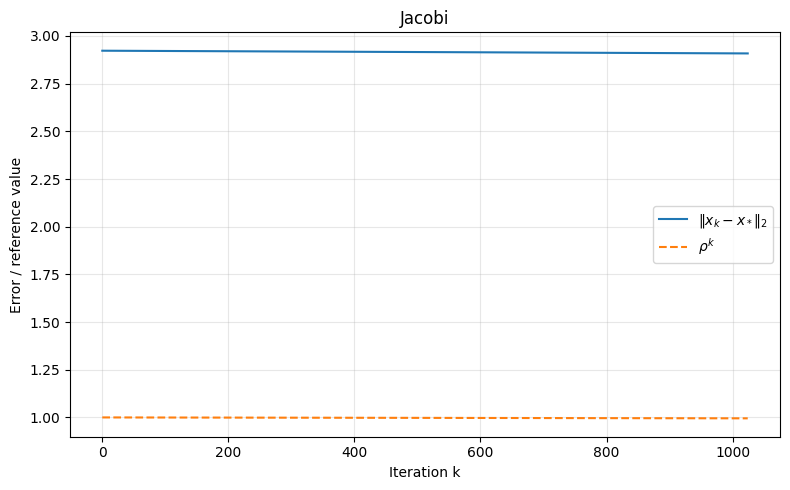

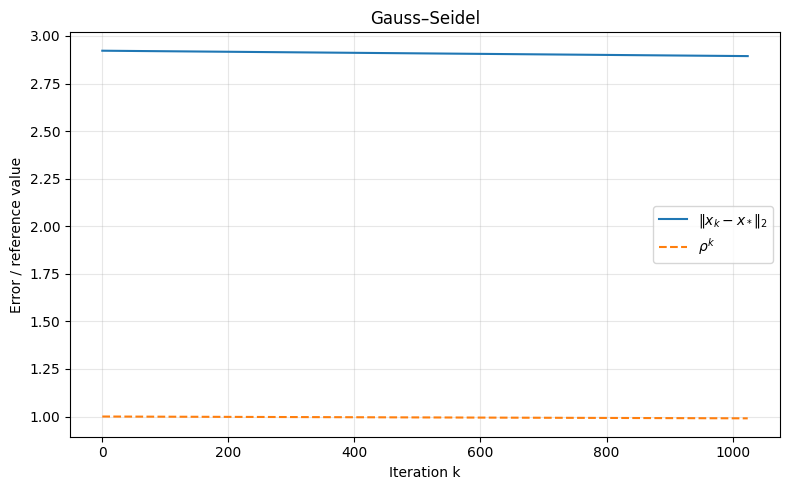

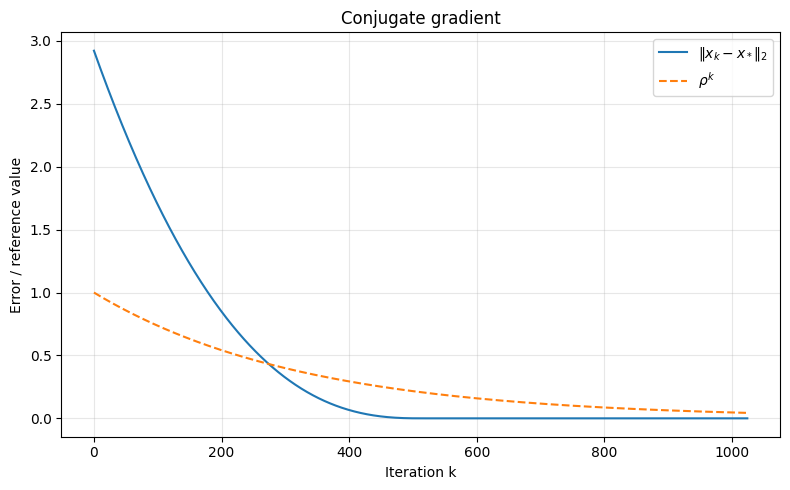

In [22]:
def plot_errors(errors, rho, title):
    plt.figure(figsize=(8, 5))

    plt.plot(
        iterations, errors,
        label=r"$\|x_k-x_*\|_2$"
    )

    plt.plot(
        iterations, rho**iterations,
        "--", label=r"$\rho^k$"
    )

    plt.xlabel("Iteration k")
    plt.ylabel("Error / reference value")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()


plot_errors(errors_j, rho_j, "Jacobi")
plot_errors(errors_gs, rho_gs, "Gauss–Seidel")
plot_errors(errors_cg, rho_cg, "Conjugate gradient")

plt.show()

See here that Conjugate Gradient Method converged the fastest reaching near machine precision in 512 steps. Its search steps preserve the progress made earlier, while Gauss-Seidel and Jacobi reduce the error slowly, taking about 1024 iterations before convergence.